In [1]:
import sys
sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

# Synthetic + Wikitext

In [2]:
data = get_runs_data(
    tag="synthetic-wiki", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ]
)

wandb: Currently logged in as: r-alvarezlucendo16 (minigpttu) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Found 2 runs with tag 'synthetic-wiki'


In [3]:
show_config_differences(data)

,cfg.dataset.total_size
_run_id,
66t1dax2,500
vyqye90h,1000


In [4]:
use_digit_tokens = data["cfg.dataset.use_digit_tokens"].unique()[0]
print(f"Using digit tokens: {use_digit_tokens}")

Using digit tokens: True


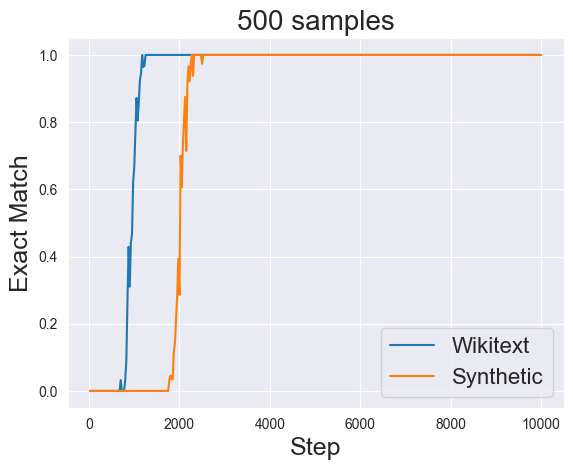

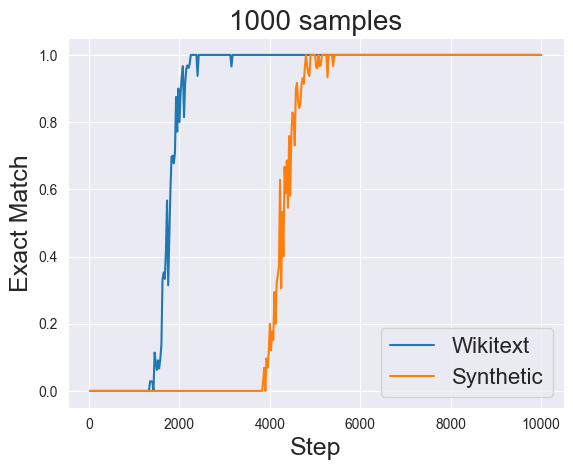

In [5]:
groups = data.groupby('cfg.dataset.total_size')[["train/exact_match_wikitext", "train/exact_match_synthetic", "train/global_step"]]
for total_size, group in groups:
    plt.figure()
    steps = group["train/global_step"].to_list()
    em_wiki = group["train/exact_match_wikitext"].to_list()
    em_synth = group["train/exact_match_synthetic"].to_list()
    plt.plot(steps, em_wiki, label="Wikitext")
    plt.plot(steps, em_synth, label="Synthetic")
    plt.title(f'{total_size} samples', fontsize=20)
    plt.xlabel('Step', fontsize=18)
    plt.ylabel('Exact Match', fontsize=18)
    plt.legend(fontsize=16)
    plt.savefig(f'figures/hybrid-synthetic-digits-vocab-{total_size}.pdf')

# Wikitext + shuffled wikitext

In [6]:
data = get_runs_data(
    tag="wiki-shuffle", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_wikitext-shuffled"
    ]
)

Found 2 runs with tag 'wiki-shuffle'


In [7]:
show_config_differences(data)

,cfg.dataset.total_size
_run_id,
jfn8dkjp,500
m2rt1eoh,1000


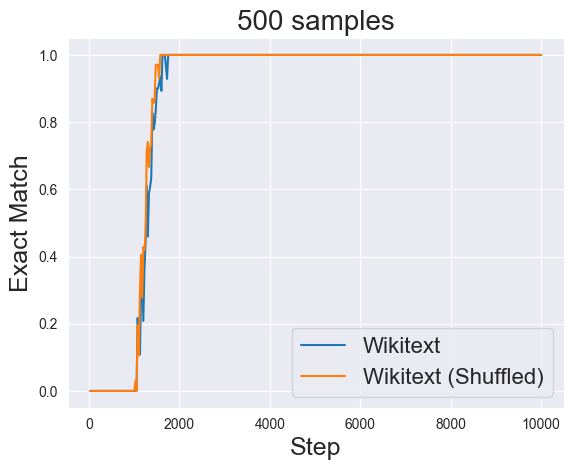

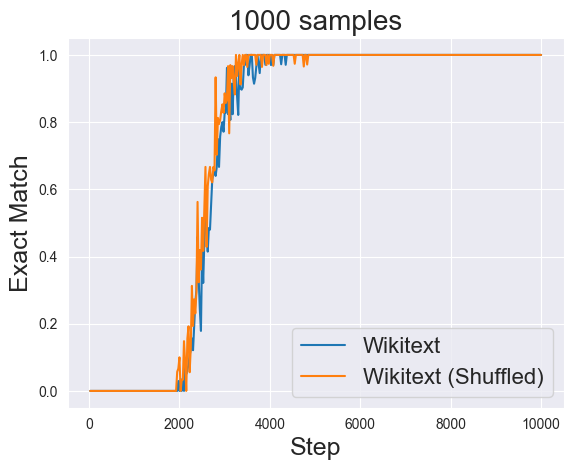

In [8]:
groups = data.groupby('cfg.dataset.total_size')[["train/exact_match_wikitext", "train/exact_match_wikitext-shuffled", "train/global_step"]]
for total_size, group in groups:
    plt.figure()
    steps = group["train/global_step"].to_list()
    em_wiki = group["train/exact_match_wikitext"].to_list()
    em_wiki_shuffled = group["train/exact_match_wikitext-shuffled"].to_list()
    plt.plot(steps, em_wiki, label="Wikitext")
    plt.plot(steps, em_wiki_shuffled, label="Wikitext (Shuffled)")
    plt.title(f'{total_size} samples', fontsize=20)
    plt.xlabel('Step', fontsize=18)
    plt.ylabel('Exact Match', fontsize=18)
    plt.legend(fontsize=16)
    plt.savefig(f'figures/hybrid-wiki-shuffle-{total_size}.pdf')

# Synthetic + Wikitext [GPT2 Vocab] 

In [9]:
data = get_runs_data(
    tag="synthetic-wiki-full-vocab", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ]
)

Found 2 runs with tag 'synthetic-wiki-full-vocab'


In [10]:
show_config_differences(data)

,cfg.dataset.total_size
_run_id,
2xrhpuoc,1000
38h60cwr,500


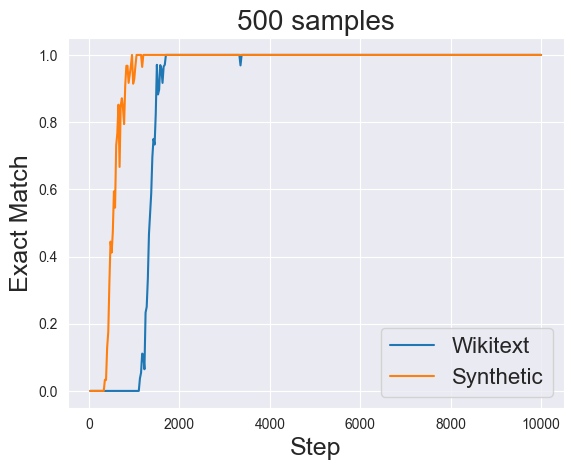

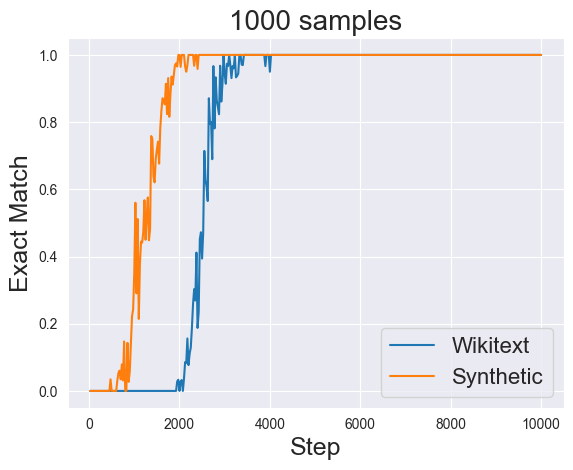

In [11]:
groups = data.groupby('cfg.dataset.total_size')[["train/exact_match_wikitext", "train/exact_match_synthetic", "train/global_step"]]
for total_size, group in groups:
    plt.figure()
    steps = group["train/global_step"].to_list()
    em_wiki = group["train/exact_match_wikitext"].to_list()
    em_synth = group["train/exact_match_synthetic"].to_list()
    plt.plot(steps, em_wiki, label="Wikitext")
    plt.plot(steps, em_synth, label="Synthetic")
    plt.title(f'{total_size} samples', fontsize=20)
    plt.xlabel('Step', fontsize=18)
    plt.ylabel('Exact Match', fontsize=18)
    plt.legend(fontsize=16)
    plt.savefig(f'figures/hybrid-synthetic-gpt2-vocab-{total_size}.pdf')

# Week 6: Repeated wikikitext & novel shuffled wikitext

In [12]:
data = get_runs_data(
    tag="week-6", 
    metrics=[
        "train/exact_match_repeated"
    ]
)

Found 3 runs with tag 'week-6'


In [13]:
show_config_differences(data)

,cfg.dataset._target_,cfg.dataset.shuffle_fresh_pool
_run_id,,
5eu5n6g2,dataset.WikiTextDataset,False
fuzjlt5d,dataset.WikiTextDataset,True
gvrgcl4n,dataset.SyntheticDataset,None


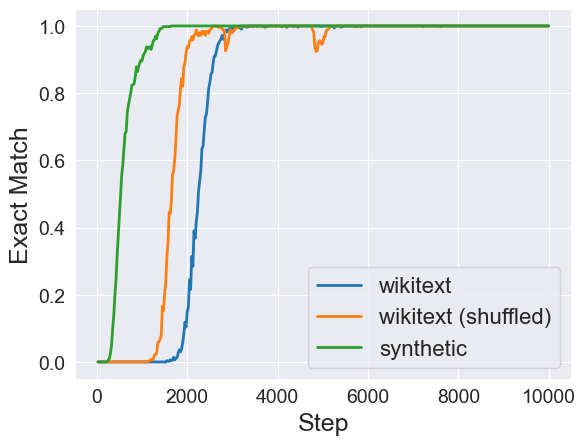

In [14]:
groups = data.groupby(["_run_id", "cfg.dataset._target_", "cfg.dataset.shuffle_fresh_pool"], dropna=False)[["train/exact_match_repeated", "train/global_step"]]
for (_, dataset_target, wiki_shuffle), group in groups:
    dataset_type = "wikitext" if "WikiTextDataset" in dataset_target else "synthetic" 
    if wiki_shuffle is not None and wiki_shuffle == True:
        dataset_type += " (shuffled)"

    max_steps = 10000
    steps = group["train/global_step"].to_list()
    em_repeated = group["train/exact_match_repeated"].to_list()
    steps = [step for step in steps if step <= max_steps]
    em_repeated = em_repeated[:len(steps)]
    plt.plot(steps, em_repeated, label=dataset_type, linewidth=2)
    plt.ylabel('Exact Match', fontsize=18)
    plt.xlabel('Step', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=16)
    plt.savefig('figures/week6-wikitext-suffled.pdf')


